# Лабораторная работа №2

ФИО: Шеранов Александр Сергеевич  
Группа: БИСТ-24-ПО-1  

Отправлять можно следующими способами:
1. Запушить этот ноутбук в GitHub в репозиторий, где у вас лежат ноутбуки с лабами

Deadlines:
- Занятие №6

Что необходимо сделать:  
**В общих чертах просто провести EDA** (но обычно это не бывает просто)
## Читайте задание внимательно

Исходные данные:
1. В [табличке](https://docs.google.com/spreadsheets/d/1NOE0D4JQgD6LbvUqWboUI1TFj4P87ugbqUTDquxlGEI/edit?usp=sharing) необходимо узнать название своего датасета 
2. Скачать нужны вам данные можно в [Google Drive](https://drive.google.com/drive/folders/1sbsjBsJ_ln0XgXCI9R6s17pvyvApgcwF?usp=sharing)
  
---
Теперь по пунктам, что я от вас жду:  
1. **Найти** в таблице (из исходных данных) название своего датасета
2. **Описать** кратко постановку задачи, что от вас хотят. Какие есть переменные. Целевое событие непрерывно (предсказываем число от -$\infty$ до $\infty$) либо дискретно (предсказываем класс из конечного множества вариантов, например 0 или 1, или какое-то число в диапазоне [0; 10])
3. Построить распределение целевой переменной в виде гистограммы, сделать промежуточные выводы (обратите внимание на однородоность распределения и возможный дисбаланс). Посчитайте количество уникальных значений целевой переменной.
4. Выведите основные статистики по переменным в датасете (для этого есть готовый метод в pandas, он считает count, min, max, mean, 25%, 50% и пр.). Это делается **одним** методом (вы его знаете).
5. Выведите основную информацию по датасету (сколько всего колонок, каких они типов, сколько в них non-null элементов). Это делается **одним** методом (вы его знаете).
6. Посчитайте количество пропусков (NaN, Null, null, None) элементов во всех колонках. Предположите, почему эти пропуски могли возникнуть, и как их можно было бы заменить. 
7. Постройте гистограммы 5 любых признаков (из множества `X`, или как оно изначально у нас называется `data.data`). Если видите какое-то смещение, несимметричность и прочее, опишите это словами в ноутбуке.
8. Постройте графики зависимости 5 любых (на ваш выбор) переменных от целевой переменной (если переменных меньше, чем 5, то сделайте столько, сколько получится). Сделайте вывод, можно ли использовать эти переменные для прогнозирования целевой переменной (иначе говоря, есть ли какая-то взаимосвязь между y-переменной и X-переменной)  
9. _extra_ (необязательно). Посмотрите на зависимость двух переменных одновременно от целевой переменной. То есть по оси OX должна быть переменная $X_{n}$, по оси OY -- переменная $X_{k}$. И у вас будет две кривые (два облака точек) в разрезе целевой переменной. Либо вы можете построить похожее для категориальных признаков, но необходимо будет прочитать про heatmap. 

---
P.S.  
Просьба -- делать каждое задание в отдельных ячейках и с отдельными заголовками (как пункт 1 и 2 в этом ноутбуке) типа  
- Заголовок
- Ячейки с кодом
- Другой заголовок
- Другие ячейки с кодом

## 1. Датасет и загрузка данных

Вариант — **Red Wine Quality**: https://www.kaggle.com/datasets/uciml/red-wine-quality-cortez-et-al-2009 . Использован файл `winequality-red.csv` из предоставленного преподавателем архива `nn_ml_datasets`.

Каждая строка описывает образец красного вина, столбцы содержат физико-химические характеристики и оценку качества `quality`. Данные находятся в `data/`, ноутбук — в `src/`. Сеть для повторного запуска не требуется. Файл в этом варианте разделён запятыми.

In [1]:
from pathlib import Path
import hashlib
import io
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from IPython.display import display, Image as DisplayImage

ROOT = Path.cwd() if (Path.cwd() / "src").is_dir() else Path.cwd().parent
DATA_PATH = ROOT / "data" / "winequality-red.csv"
data = pd.read_csv(DATA_PATH, sep=",")
TARGET = "quality"
FEATURES = ["alcohol", "volatile acidity", "sulphates", "citric acid", "total sulfur dioxide"]
plt.rcParams.update({"figure.dpi": 110, "font.size": 10})

def show_plot(fig):
    buffer = io.BytesIO()
    fig.savefig(buffer, format="png", bbox_inches="tight")
    display(DisplayImage(data=buffer.getvalue()))
    plt.close(fig)

print("Размер таблицы:", data.shape)
print("SHA-256 файла:", hashlib.sha256(DATA_PATH.read_bytes()).hexdigest())
display(data.head())

Размер таблицы: (1599, 12)
SHA-256 файла: d6a0d9bd24806944818795f22500c46cb6424cbff517aacda36595d3ed9b2daa


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5


## 2. Описание постановки задачи

Задача — по 11 физико-химическим характеристикам определить оценку качества вина. Целевая переменная `quality` — **дискретная порядковая оценка**. В этой работе рассматривается постановка многоклассовой классификации: каждая наблюдаемая оценка является отдельным классом. Порядок оценок содержателен; возможна и регрессионная постановка, однако она требует отдельного выбора модели и метрик. В ЛР №2 выполняется только EDA, модели не обучаются.

| Признак | Содержание |
| --- | --- |
| `fixed acidity` | Фиксированная кислотность |
| `volatile acidity` | Летучая кислотность |
| `citric acid` | Содержание лимонной кислоты |
| `residual sugar` | Остаточный сахар |
| `chlorides` | Содержание хлоридов |
| `free sulfur dioxide` | Свободный диоксид серы |
| `total sulfur dioxide` | Общий диоксид серы |
| `density` | Плотность |
| `pH` | Водородный показатель |
| `sulphates` | Содержание сульфатов |
| `alcohol` | Содержание алкоголя |
| `quality` | Целевая оценка качества |

Цель не включается в набор входных признаков. Практический пример — предварительная оценка качества образца по лабораторным измерениям.

In [2]:
X = data.drop(columns=TARGET)
y = data[TARGET]
print("Число признаков:", X.shape[1])
print("Цель:", y.name, "; тип:", y.dtype)
print("Уникальные оценки:", sorted(y.unique()))
print("Число классов:", y.nunique())

Число признаков: 11
Цель: quality ; тип: int64
Уникальные оценки: [np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8)]
Число классов: 6


## 3. Распределение целевой переменной

Доля оценок 5 и 6: 82.49%
Отношение размеров крупнейшего и наименьшего классов: 68.1


,count,percent
quality,,
3,10,0.63
4,53,3.31
5,681,42.59
6,638,39.90
7,199,12.45
8,18,1.13


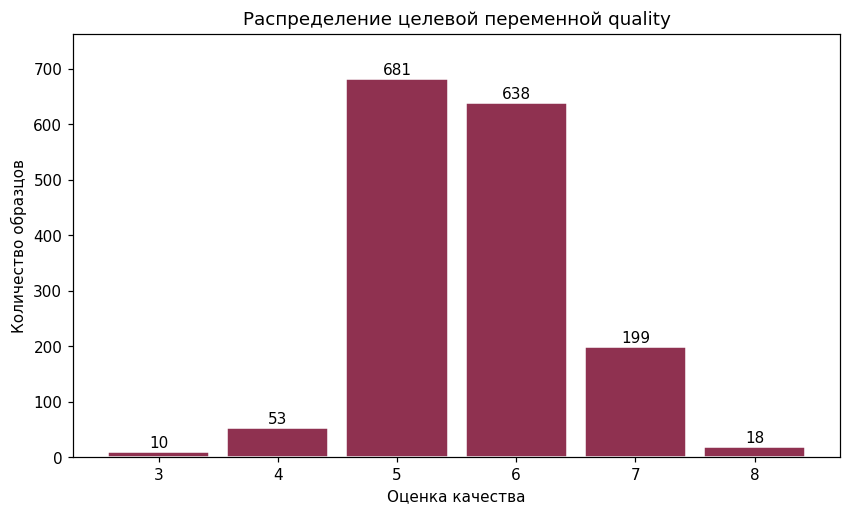

In [3]:
counts = y.value_counts().sort_index()
class_table = counts.rename("count").to_frame()
class_table["percent"] = counts / len(y) * 100
display(class_table.round(2))
fig, ax = plt.subplots(figsize=(9, 5))
ax.hist(y, bins=np.arange(y.min() - .5, y.max() + 1.5, 1),
        color="#8f3150", edgecolor="white", rwidth=.85)
ax.set(xticks=counts.index, xlabel="Оценка качества", ylabel="Количество образцов",
       title="Распределение целевой переменной quality")
for grade, count in counts.items():
    ax.text(grade, count + 8, str(count), ha="center")
ax.set_ylim(0, counts.max() * 1.12)
show_plot(fig)
print(f"Доля оценок 5 и 6: {y.isin([5, 6]).mean():.2%}")
print(f"Отношение размеров крупнейшего и наименьшего классов: {counts.max()/counts.min():.1f}")

**Вывод.** В выборке шесть классов: оценки от 3 до 8. Чаще встречаются 5 (681 образец) и 6 (638 образцов): вместе 82,49% данных. Оценок 3 всего 10, оценок 8 — 18. Распределение существенно несбалансировано: отношение размеров наибольшего и наименьшего классов — 68,1. Поэтому accuracy будущей модели недостаточна сама по себе; нужно учитывать macro-F1 и показатели по отдельным классам. Отсутствие оценок за пределами 3–8 характеризует эту выборку, а не обязательно всю шкалу оценивания.

## 4. Основные статистики по переменным

In [4]:
display(data.describe())

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
count,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000
mean,8.319637,0.527821,0.270976,2.538806,0.087467,15.874922,46.467792,0.996747,3.311113,0.658149,10.422983,5.636023
std,1.741096,0.179060,0.194801,1.409928,0.047065,10.460157,32.895324,0.001887,0.154386,0.169507,1.065668,0.807569
min,4.600000,0.120000,0.000000,0.900000,0.012000,1.000000,6.000000,0.990070,2.740000,0.330000,8.400000,3.000000
25%,7.100000,0.390000,0.090000,1.900000,0.070000,7.000000,22.000000,0.995600,3.210000,0.550000,9.500000,5.000000
50%,7.900000,0.520000,0.260000,2.200000,0.079000,14.000000,38.000000,0.996750,3.310000,0.620000,10.200000,6.000000
75%,9.200000,0.640000,0.420000,2.600000,0.090000,21.000000,62.000000,0.997835,3.400000,0.730000,11.100000,6.000000
max,15.900000,1.580000,1.000000,15.500000,0.611000,72.000000,289.000000,1.003690,4.010000,2.000000,14.900000,8.000000


**Вывод.** Все столбцы численные, но их диапазоны и единицы измерения различаются. Например, `density` близка к 1, а `total sulfur dioxide` измеряется десятками и сотнями. Для моделей, чувствительных к масштабу, понадобится масштабирование. Его параметры следует оценивать только по обучающей части. Максимальные значения некоторых признаков заметно превосходят третий квартиль; это повод изучить хвосты распределений, а не автоматически удалять такие строки.

## 5. Основная информация о датасете

In [5]:
data.info()
print("Строк:", data.shape[0], "; столбцов:", data.shape[1])
print("Количество столбцов каждого типа:")
display(data.dtypes.astype(str).value_counts().rename("columns_count").to_frame())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1599 entries, 0 to 1598
Data columns (total 12 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed acidity         1599 non-null   float64
 1   volatile acidity      1599 non-null   float64
 2   citric acid           1599 non-null   float64
 3   residual sugar        1599 non-null   float64
 4   chlorides             1599 non-null   float64
 5   free sulfur dioxide   1599 non-null   float64
 6   total sulfur dioxide  1599 non-null   float64
 7   density               1599 non-null   float64
 8   pH                    1599 non-null   float64
 9   sulphates             1599 non-null   float64
 10  alcohol               1599 non-null   float64
 11  quality               1599 non-null   int64  
dtypes: float64(11), int64(1)
memory usage: 150.0 KB
Строк: 1599 ; столбцов: 12
Количество столбцов каждого типа:


,columns_count
float64,11
int64,1


**Вывод.** В таблице 1599 строк и 12 столбцов: 11 входных признаков типа `float64` и целевая переменная `quality` типа `int64`. В каждом столбце по 1599 непустых значений. Числовой тип целевой переменной не делает выбранную задачу регрессией: здесь оценки рассматриваются как классы.

## 6. Пропуски, повторы и контроль качества данных

In [6]:
missing = data.isna().sum().rename("missing").to_frame()
missing["percent"] = missing["missing"] / len(data) * 100
display(missing)
print("Всего пропущенных ячеек:", int(data.isna().sum().sum()))
print("Бесконечных значений:", int(np.isinf(data.select_dtypes(include="number")).sum().sum()))
print("Полностью повторных строк сверх первых:", int(data.duplicated().sum()))
print("Уникальных полных строк:", len(data.drop_duplicates()))
print("Строк с пустым текстом:", int(data.astype(str).apply(lambda s: s.str.strip().eq("")).any(axis=1).sum()))
feature_groups = data.groupby(list(X.columns))[TARGET].nunique()
print("Групп одинаковых признаков с различными целями:", int((feature_groups > 1).sum()))

Всего пропущенных ячеек: 0
Бесконечных значений: 0
Полностью повторных строк сверх первых: 240
Уникальных полных строк: 1359
Строк с пустым текстом: 0
Групп одинаковых признаков с различными целями: 0


,missing,percent
fixed acidity,0,0.0
volatile acidity,0,0.0
citric acid,0,0.0
residual sugar,0,0.0
chlorides,0,0.0
free sulfur dioxide,0,0.0
total sulfur dioxide,0,0.0
density,0,0.0
pH,0,0.0
sulphates,0,0.0


**Вывод.** Пропуски и бесконечные значения отсутствуют, поэтому заполнять их не требуется. Обнаружено 240 повторных строк сверх первых; уникальных полных строк — 1359. Идентификаторов образцов нет, поэтому нельзя доказать, являются ли повторы ошибкой загрузки или повторными наблюдениями. В EDA исходные строки сохранены, чтобы описать предоставленную выборку без произвольных изменений.

При дальнейшем обучении одинаковые наблюдения нельзя распределять между train и test: это создаёт риск утечки. Следует заранее выбрать удаление повторов либо групповое разбиение по одинаковым входным признакам.

Если бы пропуски присутствовали, возможными причинами были бы отсутствующие измерения или ошибки экспорта. Для численных признаков можно рассмотреть медиану, для категориальных — наиболее частое значение или отдельную категорию. Стратегию нужно выбирать по смыслу, а параметры вычислять только на train. Неизвестную целевую оценку не следует автоматически подменять средним классом.

## 7. Гистограммы пяти входных признаков

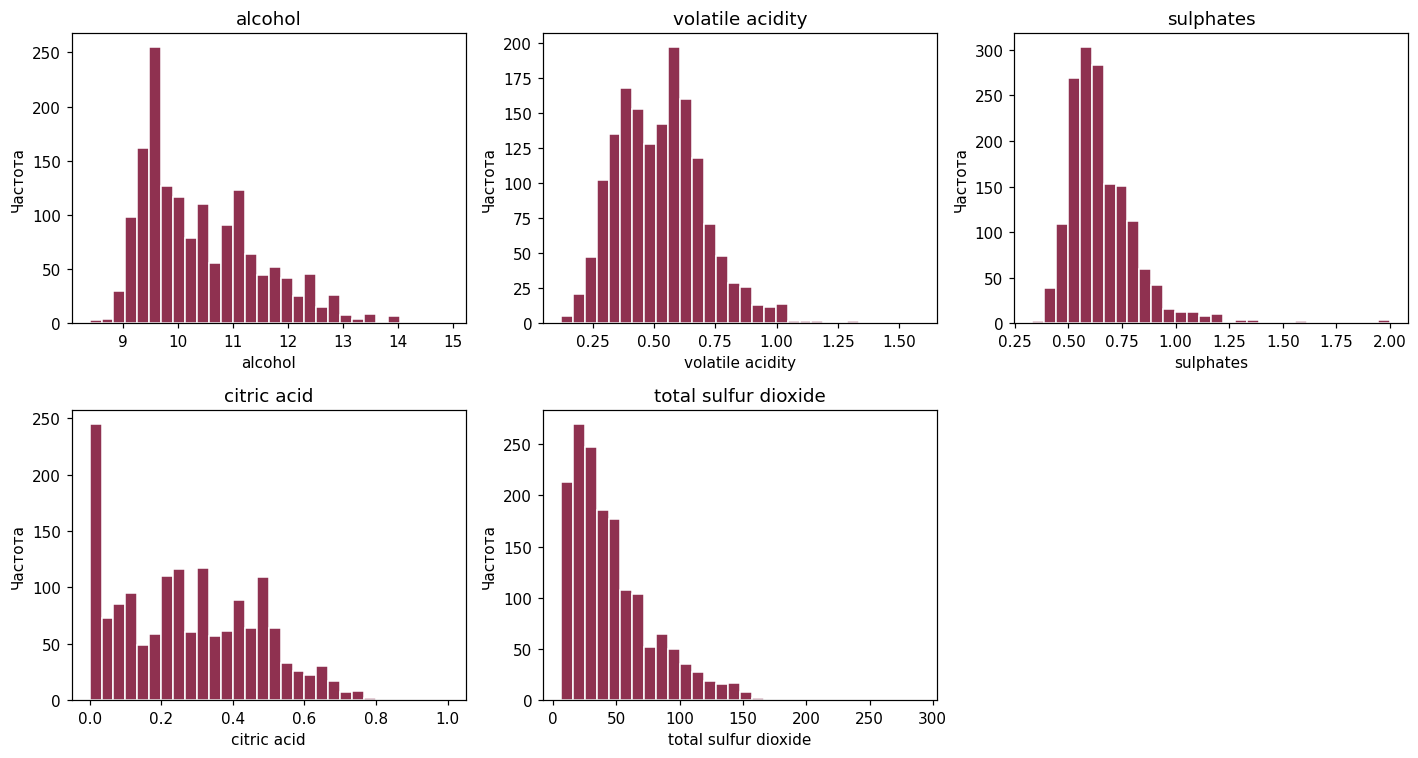

,mean,median,std,skew
alcohol,10.4230,10.20,1.0657,0.8608
volatile acidity,0.5278,0.52,0.1791,0.6716
sulphates,0.6581,0.62,0.1695,2.4287
citric acid,0.2710,0.26,0.1948,0.3183
total sulfur dioxide,46.4678,38.00,32.8953,1.5155


In [7]:
fig, axes = plt.subplots(2, 3, figsize=(13, 7))
for ax, feature in zip(axes.flat, FEATURES):
    ax.hist(data[feature], bins=30, color="#8f3150", edgecolor="white")
    ax.set(title=feature, xlabel=feature, ylabel="Частота")
axes.flat[-1].axis("off")
fig.tight_layout()
show_plot(fig)
shape = data[FEATURES].agg(["mean", "median", "std", "skew"]).T
display(shape.round(4))

**Выводы по распределениям.**

- `alcohol`: основная масса значений лежит в нижней части диапазона, есть правый хвост; асимметрия 0.861.
- `volatile acidity`: распределение правосторонне асимметрично (0.672), есть высокие значения летучей кислотности.
- `sulphates`: выраженный правый хвост; асимметрия 2.429. Редкие высокие значения требуют проверки по предметному смыслу.
- `citric acid`: встречаются нулевые и малые значения; асимметрия 0.318. Ноль не трактуется как пропуск без дополнительных оснований.
- `total sulfur dioxide`: выраженный правый хвост; асимметрия 1.516.

Ни одну из этих величин нельзя считать нормально распределённой только по визуальному сходству. Редкие значения не удаляются автоматически: сначала нужно проверить корректность измерений и влияние на задачу.

## 8. Зависимость пяти признаков от целевой переменной

Медианы признаков по оценкам:


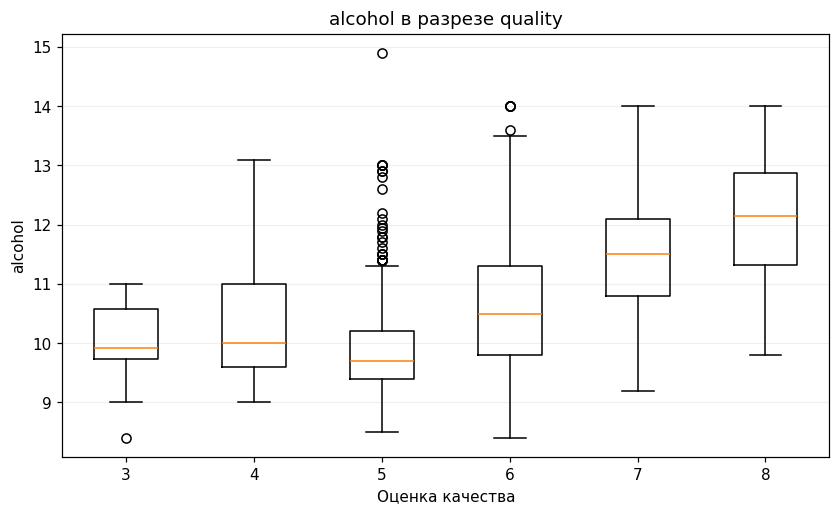

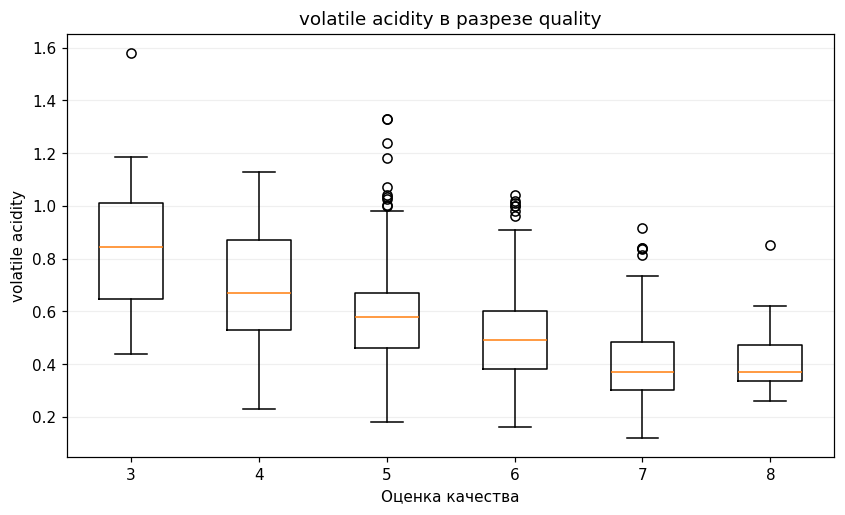

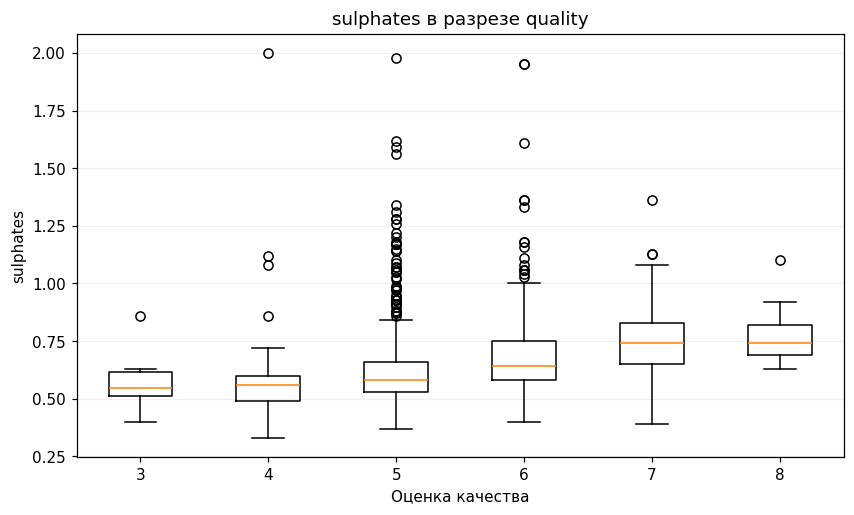

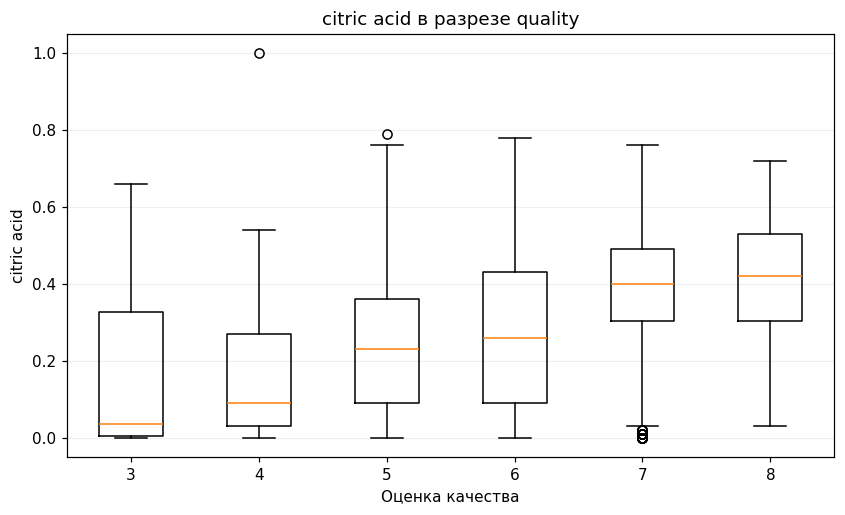

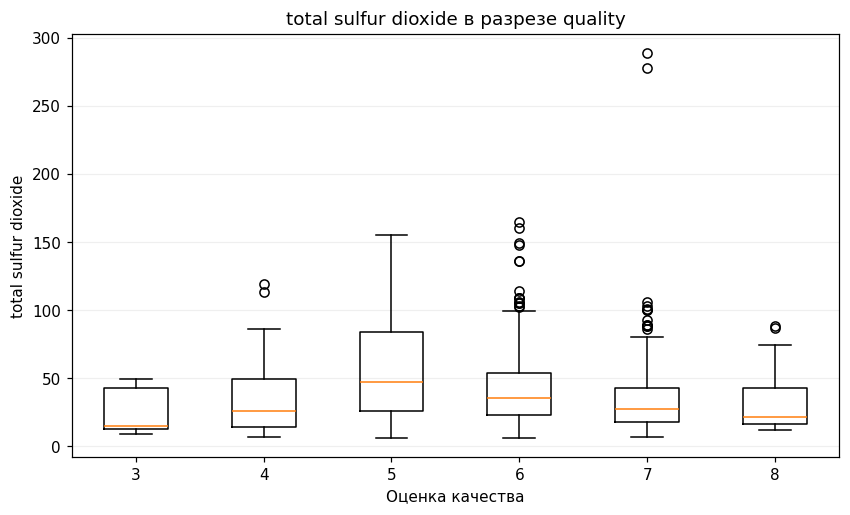

,Pearson,Spearman
alcohol,0.4762,0.4785
volatile acidity,-0.3906,-0.3806
sulphates,0.2514,0.3771
citric acid,0.2264,0.2135
total sulfur dioxide,-0.1851,-0.1967


,alcohol,volatile acidity,sulphates,citric acid,total sulfur dioxide
quality,,,,,
3,9.925,0.845,0.545,0.035,15.0
4,10.000,0.670,0.560,0.090,26.0
5,9.700,0.580,0.580,0.230,47.0
6,10.500,0.490,0.640,0.260,35.0
7,11.500,0.370,0.740,0.400,27.0
8,12.150,0.370,0.740,0.420,21.5


In [8]:
# quality дискретна: boxplot удобнее линии, искусственно соединяющей разные образцы.
order = sorted(y.unique())
for feature in FEATURES:
    fig, ax = plt.subplots(figsize=(9, 5))
    groups = [data.loc[y.eq(grade), feature].to_numpy() for grade in order]
    ax.boxplot(groups, tick_labels=order, showfliers=True)
    ax.set(xlabel="Оценка качества", ylabel=feature, title=f"{feature} в разрезе quality")
    ax.grid(axis="y", alpha=.2)
    show_plot(fig)

association = pd.DataFrame({
    "Pearson": data[FEATURES].corrwith(y, method="pearson"),
    "Spearman": data[FEATURES].corrwith(y, method="spearman")
})
display(association.round(4))
print("Медианы признаков по оценкам:")
display(data.groupby(TARGET)[FEATURES].median().round(4))

**Выводы о связи с качеством.**

- `alcohol`: положительная связь; корреляция Пирсона 0.476. Среди выбранных признаков это наиболее сильная линейная связь с оценкой.
- `volatile acidity`: отрицательная связь (-0.391); более высоким оценкам в целом соответствуют меньшие значения летучей кислотности.
- `sulphates`: положительная связь (0.251), но распределения классов перекрываются.
- `citric acid`: положительная связь (0.226), одного признака недостаточно для разделения оценок.
- `total sulfur dioxide`: слабая отрицательная линейная связь (-0.185); она не означает строгого монотонного изменения медиан каждого класса.

Эти признаки можно рассматривать как кандидаты для прогнозирования, но их полезность проверяется по качеству модели на отложенных данных. Показаны и Пирсон, и Спирмен: `quality` имеет порядковый смысл, а равные расстояния между соседними оценками не гарантированы. Корреляция не доказывает причинность. В редких классах 3 и 8 мало наблюдений, поэтому выводы по их распределениям менее устойчивы. Перекрытие ящиков показывает, что простого разделения по одному признаку нет.

## 9. Дополнительно: два признака одновременно и корреляции

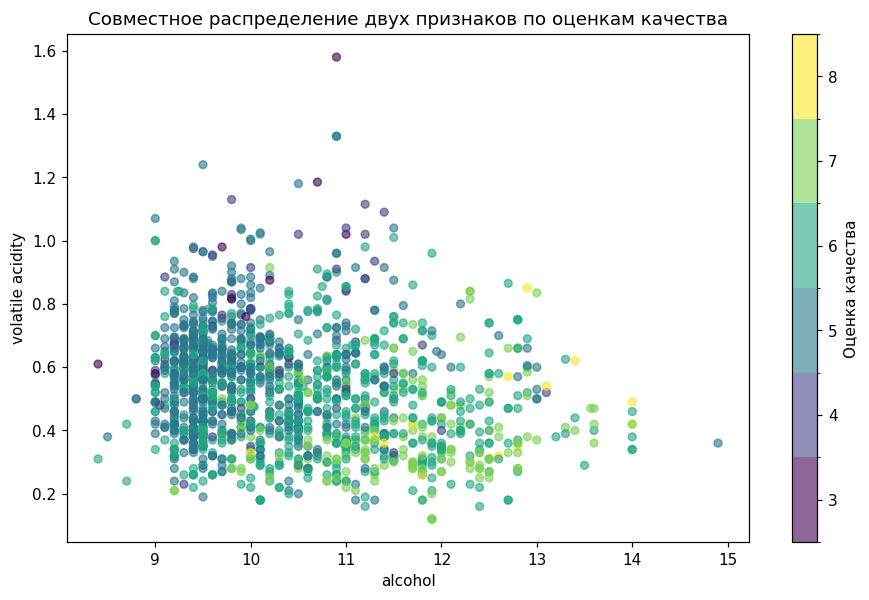

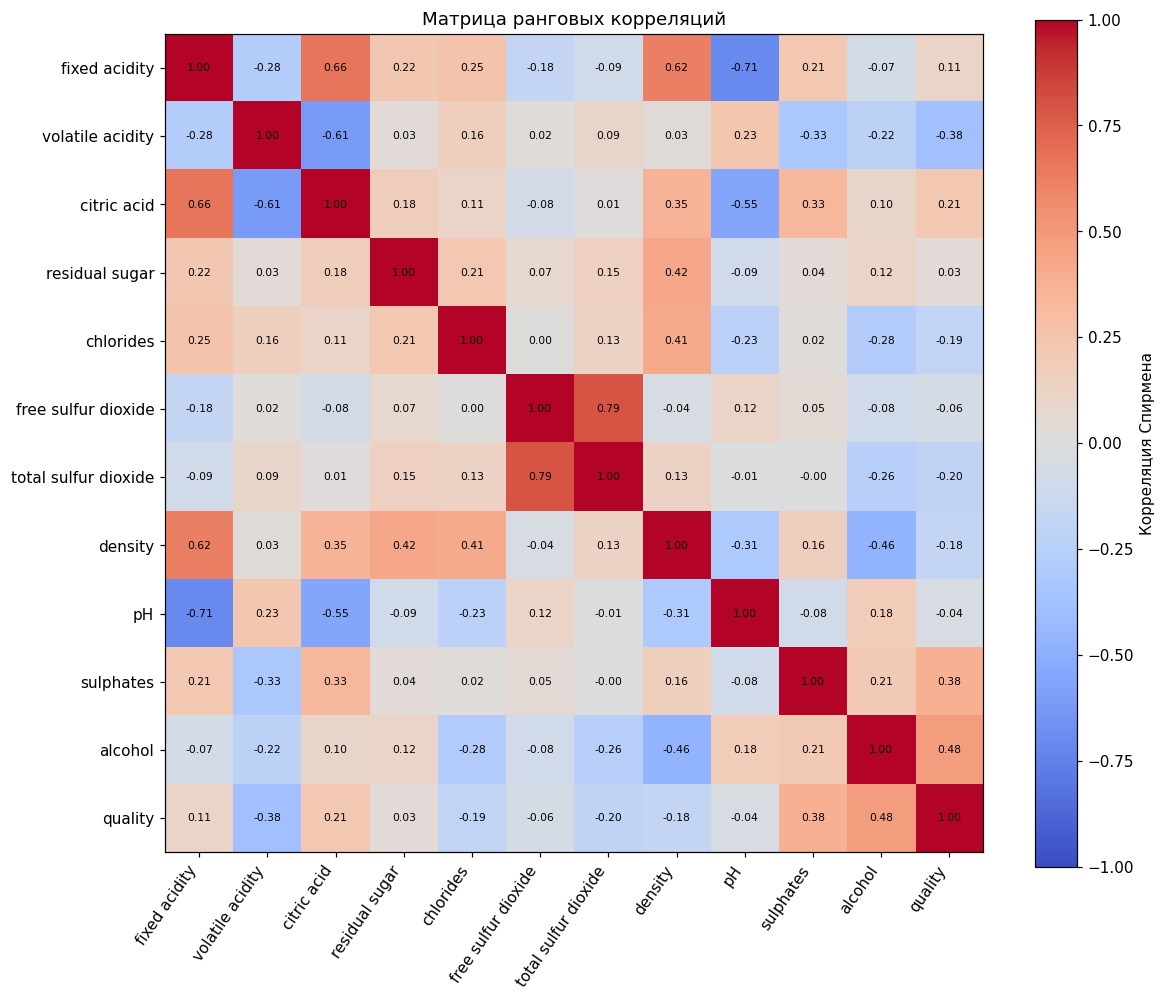

In [9]:
from matplotlib.colors import BoundaryNorm
fig, ax = plt.subplots(figsize=(10, 6))
cmap = plt.get_cmap("viridis", len(order))
norm = BoundaryNorm(np.arange(min(order) - .5, max(order) + 1.5, 1), cmap.N)
points = ax.scatter(data["alcohol"], data["volatile acidity"], c=y,
                    cmap=cmap, norm=norm, s=26, alpha=.6)
fig.colorbar(points, ax=ax, ticks=order, label="Оценка качества")
ax.set(xlabel="alcohol", ylabel="volatile acidity",
       title="Совместное распределение двух признаков по оценкам качества")
show_plot(fig)

corr = data.corr(method="spearman")
fig, ax = plt.subplots(figsize=(12, 10))
im = ax.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr)), corr.columns, rotation=55, ha="right")
ax.set_yticks(range(len(corr)), corr.index)
for i in range(len(corr)):
    for j in range(len(corr)):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=7)
fig.colorbar(im, ax=ax, label="Корреляция Спирмена")
ax.set_title("Матрица ранговых корреляций")
show_plot(fig)

**Вывод.** На плоскости `alcohol`–`volatile acidity` оценки частично перекрываются, хотя более высокие оценки чаще располагаются в области большего содержания алкоголя и меньшей летучей кислотности. Ни одна граница качества визуально не является точной. Из-за наложения точек график не заменяет подсчёт частот. Матрица корреляций позволяет увидеть взаимосвязанные входные признаки; сильные корреляции важно учитывать при интерпретации линейных моделей.

## Итог

Выполнены все обязательные пункты и дополнительный анализ двух признаков. Таблица содержит 1599 образцов, 11 признаков и порядковую целевую переменную с шестью наблюдаемыми классами. Пропуски не обнаружены, но есть 240 полных повторов и выраженный дисбаланс оценок. Из пяти выбранных признаков наиболее сильную линейную связь с качеством имеет содержание алкоголя; летучая кислотность связана отрицательно.

Перед моделированием нужно определить стратегию обработки повторов, разделить данные с учётом классов и утечки, а затем обучать преобразования только по train. В этой лабораторной модели не обучались; точность прогнозирования не измерялась.

In [10]:
print("Лабораторная работа №2: Red Wine Quality")
print(f"Строк: {len(data)}; входных признаков: {X.shape[1]}; классов: {y.nunique()}.")
print(f"Пропусков: {data.isna().sum().sum()}; повторов сверх первых: {data.duplicated().sum()}.")
print("Все пункты EDA выполнены, таблицы и графики сохранены в ноутбуке.")

Лабораторная работа №2: Red Wine Quality
Строк: 1599; входных признаков: 11; классов: 6.
Пропусков: 0; повторов сверх первых: 240.
Все пункты EDA выполнены, таблицы и графики сохранены в ноутбуке.
